In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('doc-v-sub_anonymized.csv')
df.head()

,Record ID,Amount,Deal owner,Close Date,Opened
0,67797729678,NaN,sales agent 1,11/11/2026 16:33,11/13/2026
1,67797137292,995.0,sales agent 2,11/10/2026 11:36,11/12/2026
2,67661735686,4195.0,sales agent 1,11/9/2026 16:19,11/15/2026
3,67661660202,995.0,sales agent 3,11/9/2026 13:34,11/10/2026
4,67661724020,1195.0,sales agent 3,11/7/2026 13:51,11/9/2026


In [3]:

#Convert Close Date to Datetime object
df['close_date'] = pd.to_datetime(df['Close Date'])
df['open_date'] = pd.to_datetime(df['Opened'])

#Add colummns for Docusign Month and Year
df['close_month'] = df['close_date'].dt.month
df['open_month'] = df['open_date'].dt.month
df['year'] = df['close_date'].dt.year

#Only look at Year == 2026
current_df = df[df['year'] == 2026]
current_df = current_df.loc[:, ('Record ID', 'Deal owner', 'close_month', 'open_month')]

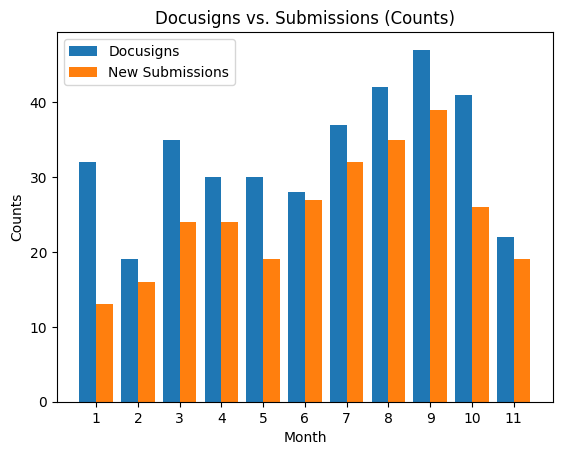

In [4]:
#Plot
closed_agg = current_df.groupby('close_month')['close_month'].agg('count').to_frame()
opened_agg = current_df.groupby('open_month')['open_month'].agg('count').to_frame()

docusign_months = closed_agg.index.tolist()
docusign_counts = closed_agg.iloc[:,0].tolist()

submission_months = opened_agg.index.tolist()[:-1]
submission_counts = opened_agg.iloc[:,0].tolist()[:-1]

#Set Figure Size
fig, ax = plt.subplots()
w, x = 0.4, np.arange(len(docusign_months))

#Plot Docusign Data
ax.bar(1 + x - w/2, docusign_counts, width = w, label= 'Docusign Counts')

#Plot Submission Data
ax.bar(1 + x + w/2, submission_counts, width = w, label= 'Submission Counts')

#Add Title and Labels
plt.title('Docusigns vs. Submissions (Counts)')
plt.xticks(1 + x, docusign_months)
plt.xlabel('Month')
plt.ylabel('Counts')
ax.legend(['Docusigns', 'New Submissions'])

plt.show()

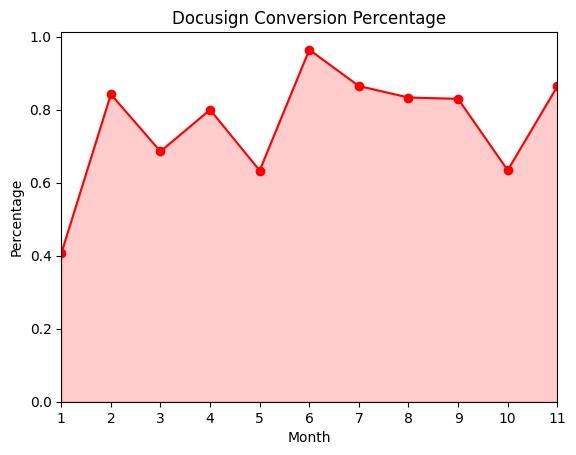

In [5]:
### Ratio Between Docusigns and New Submissions

ratios = [ x / y for x, y in zip(submission_counts, docusign_counts)]

fig,ax = plt.subplots()

ax.plot(1 + x, ratios, marker='o', color='red')
ax.fill_between(1 + x, ratios, color='red', alpha=0.2)
ax.set_ylim(bottom=0)
ax.set_xlim(left=1, right = 11)

plt.xticks(1 + x, docusign_months)
plt.title('Docusign Conversion Percentage')
plt.xlabel('Month')
plt.ylabel('Percentage')
plt.show()

In [6]:
ratio_table = pd.DataFrame(ratios, docusign_months)
print(ratio_table)

average_ratio = np.mean(ratios)
print(f'Average Ratio: {average_ratio}')

           0
1   0.406250
2   0.842105
3   0.685714
4   0.800000
5   0.633333
6   0.964286
7   0.864865
8   0.833333
9   0.829787
10  0.634146
11  0.863636
Average Ratio: 0.7597687939847052


In [7]:
### Repeat process for each sales agent

In [8]:
sales_agents = current_df['Deal owner'].unique().tolist()
sales_df = {}

for agent in sales_agents:
    sales_df[agent] = current_df[current_df['Deal owner'] == agent]

for key in sales_df.keys():
    print("\n" +"="*40)
    print(key)
    print("-"*40)
    print(sales_df[key])


sales agent 1
----------------------------------------
       Record ID     Deal owner  close_month  open_month
0    67797729678  sales agent 1           11        11.0
2    67661735686  sales agent 1           11        11.0
9    66663929146  sales agent 1           10        10.0
14   67423958193  sales agent 1           11        11.0
17   66544070819  sales agent 1           10        11.0
..           ...            ...          ...         ...
524  67797146380  sales agent 1           11         NaN
527  67661373581  sales agent 1           11         NaN
528  67424082178  sales agent 1           11         NaN
532  66949323523  sales agent 1           10         NaN
535  66637020558  sales agent 1           10         NaN

[150 rows x 4 columns]

sales agent 2
----------------------------------------
       Record ID     Deal owner  close_month  open_month
1    67797137292  sales agent 2           11        11.0
6    67368290970  sales agent 2           11        11.0
15   6736

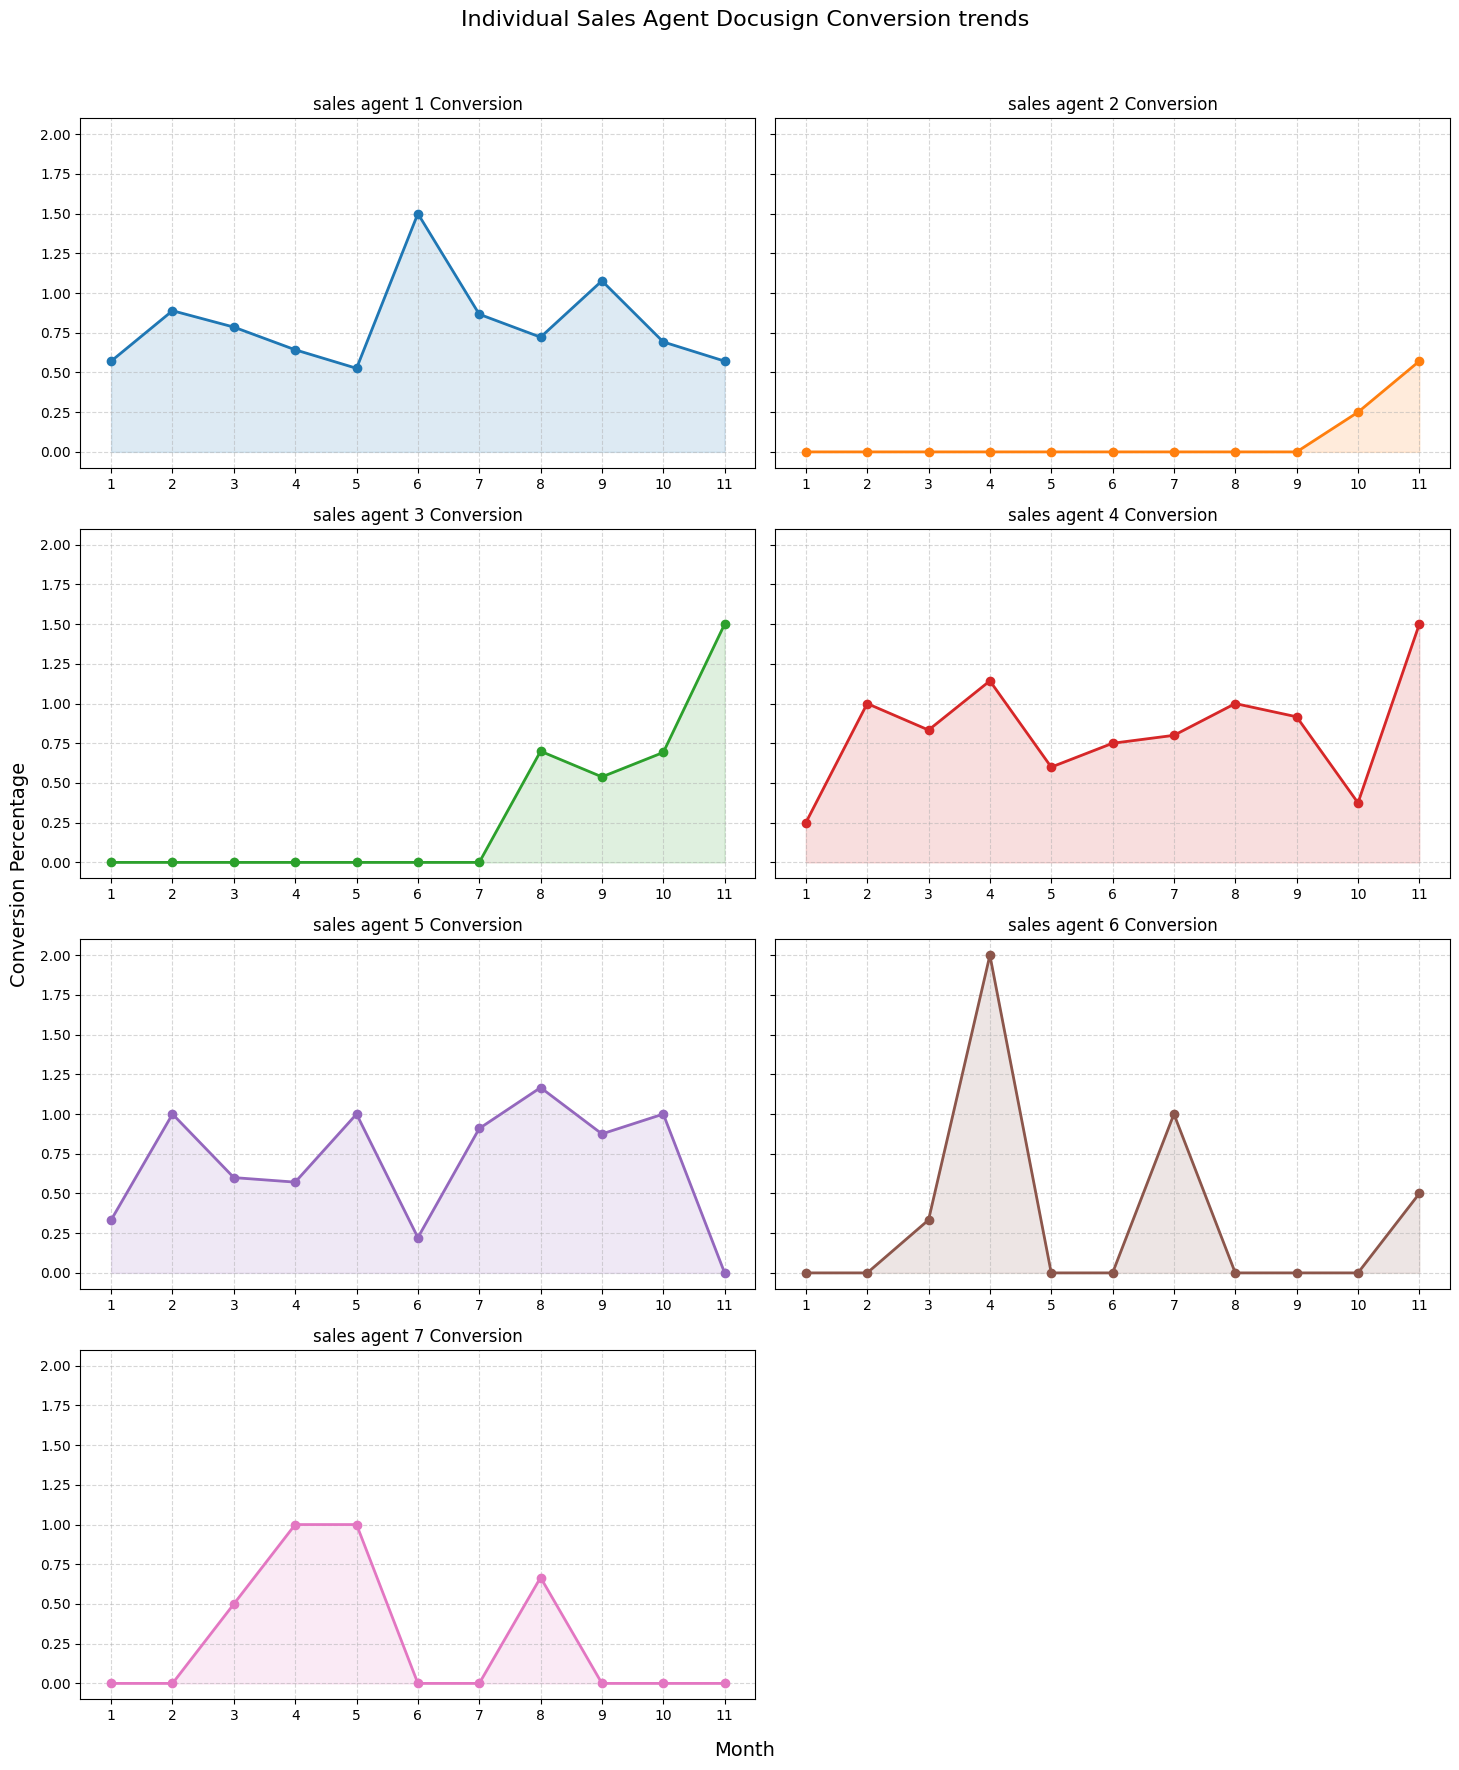

In [11]:
def report_clean(df):
    # Reindex with all possible months (1 to 11) to ensure every agent has an aligned timeline
    df_closed_agg = df.groupby('close_month')['close_month'].agg('count').reindex(range(1, 12), fill_value=0)
    df_opened_agg = df.groupby('open_month')['open_month'].agg('count').reindex(range(1, 12), fill_value=0)

    df_docusign_counts = df_closed_agg.tolist()
    df_submission_counts = df_opened_agg.tolist()

    return df_docusign_counts, df_submission_counts

ratios = {}
months = list(range(1, 12))

for key in sales_df.keys():
    df_docusign_counts, df_submission_counts = report_clean(sales_df[key])
    # Prevent division by zero if docusigns count is 0 for a month
    ratios[key] = [x / y if y > 0 else 0 for x, y in zip(df_submission_counts, df_docusign_counts)]

# Create a grid of subplots without sharing the x axis so each graph displays its own tick labels
num_agents = len(sales_df)
fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(15, 18), sharey=True)
axes = axes.flatten()  # Flatten the 2D array of axes for easy indexing

for idx, (agent, ratio_list) in enumerate(ratios.items()):
    ax = axes[idx]
    ax.plot(months, ratio_list, marker='o', color='C'+str(idx), linewidth=2)
    ax.fill_between(months, ratio_list, color='C'+str(idx), alpha=0.15)
    ax.set_title(f'{agent} Conversion', fontsize=12)
    ax.set_xticks(months)
    ax.set_ylim(-0.1, 2.1)
    ax.grid(True, linestyle='--', alpha=0.5)

# Hide any unused subplots (since we have 7 agents and 8 slots)
for idx in range(num_agents, len(axes)):
    fig.delaxes(axes[idx])

fig.suptitle('Individual Sales Agent Docusign Conversion trends', fontsize=16, y=0.98)
fig.text(0.5, 0.01, 'Month', ha='center', fontsize=14)
fig.text(0.01, 0.5, 'Conversion Percentage', va='center', rotation='vertical', fontsize=14)

plt.tight_layout(rect=[0.02, 0.02, 0.98, 0.96])
plt.show()